## Fase #5: Evaluación / Evaluation
En esta etapa del proyecto, se ha construido un modelo que parece tener alta calidad desde una perspectiva de análisis de datos. Antes de proceder a la implementación final del modelo, es importante evaluar más a fondo el modelo y revisar los pasos realizados para construir el modelo y asegurarse de que logra correctamente los objetivos definidos en la fase de comprensión del negocio. Un objetivo clave es determinar si hay algún tema importante del negocio que no se haya considerado lo suficiente. Al final de esta fase, se debe tomar una decisión sobre el uso de los resultados de la minería de datos.

### Métricas de evaluación

| Métrica | Interpretación |
|---|---|
| MAE | Error absoluto promedio en m³. Es la métrica principal por su lectura directa. |
| RMSE | Error en m³ que penaliza con mayor fuerza los desaciertos grandes. |
| Error mediano absoluto | Error típico menos sensible a valores extremos. |
| R² | Proporción de variación explicada respecto de predecir la media; puede ser negativa en prueba. |

La matriz de confusión no corresponde porque el problema final es de regresión. Además de las métricas, se revisarán errores por año y gráficos de observado frente a estimado.

In [1]:
# @title Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display  # ty: ignore[unresolved-import]
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score

from comun import ENTRADAS_CATEGORICAS, ENTRADAS_NUMERICAS, OBJETIVO, importar_modelos

In [2]:
# @title Carga de los artefactos de la fase 4

objetivo = OBJETIVO
entradas_numericas = ENTRADAS_NUMERICAS
entradas_categoricas = ENTRADAS_CATEGORICAS
entradas = entradas_numericas + entradas_categoricas

# La partición temporal que se usa acá es exactamente la de la fase 4: viene
# guardada en los artefactos. No se la recalcula desde el CSV original, porque
# ese archivo se actualiza periódicamente y entonces las filas dejarían de
# corresponderse con las observaciones y predicciones guardadas.
modelo, referencia, nombre_modelo, X_test, y_test, test_metadata = importar_modelos(
	"modelo",
	"referencia",
	"nombre_modelo",
	"X_test",
	"y_test",
	"test_metadata",
)

pred_modelo = modelo.predict(X_test)
pred_referencia = referencia.predict(X_test)

print(f"Modelo evaluado: {nombre_modelo}")
print(f"Registros de prueba: {len(X_test):,}")
print(f"Variables de entrada: {entradas}")
print(f"Objetivo: {objetivo}")

Modelo evaluado: Ridge
Registros de prueba: 691
Variables de entrada: ['longitud_rama_horizontal_m', 'cantidad_fracturas', 'tipo_terminacion']
Objetivo: agua_inyectada_m3


,modelo,MAE_m3,RMSE_m3,MedAE_m3,R2
0,Referencia: mediana,27766.281,33186.027,25282.882,-1.734
1,Ridge,8016.617,10972.655,6080.900,0.701


Decisión preliminar: el Ridge mejora la referencia en MAE (71.1%).


,id_base_fractura_adjiv,idpozo,fecha_inicio_fractura,agua_observada_m3,agua_estimada_m3,error_m3,error_absoluto_m3
671,5747,166759,2025-07-13,160827.1,74624.0,-86203.2,86203.2
473,5484,166964,2025-11-30,93526.0,147588.6,54062.6,54062.6
427,5409,166582,2025-02-13,84961.0,122195.8,37234.8,37234.8
84,4877,166179,2025-03-04,127946.0,90742.3,-37203.7,37203.7
83,4876,166169,2025-03-04,123074.0,86798.8,-36275.2,36275.2
159,5003,166779,2025-05-28,109083.2,143888.9,34805.7,34805.7
429,5411,166584,2025-02-14,90001.0,123510.3,33509.3,33509.3
160,5004,166780,2025-05-29,109282.7,142424.7,33142.0,33142.0
495,5543,166855,2025-09-09,77993.0,45154.7,-32838.3,32838.3
162,5006,166782,2025-05-29,102173.1,134656.6,32483.4,32483.4


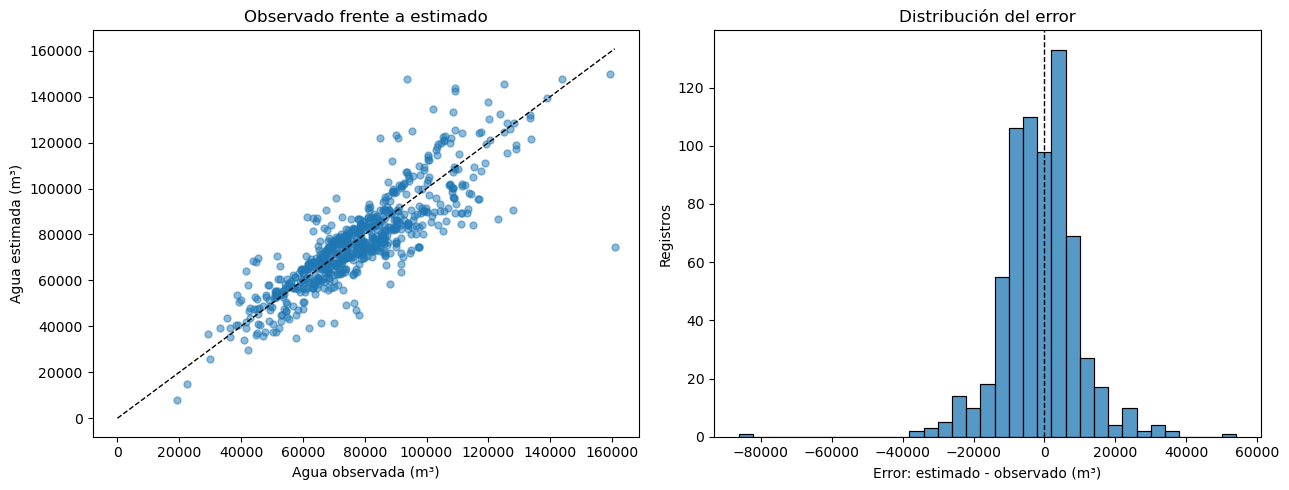

,|coeficiente|
num__cantidad_fracturas,18099.7085
cat__tipo_terminacion_Camisas deslizables,16461.3911
cat__tipo_terminacion_Camisas y punzados,13746.7170
cat__tipo_terminacion_Tapón disparo,7612.9227
cat__tipo_terminacion_Jetteo,5026.7689
num__longitud_rama_horizontal_m,3399.7294
cat__tipo_terminacion_Punzado,128.5203


Las importancias describen el uso de variables por el modelo; no prueban causalidad.


In [3]:
def calcular_metricas(nombre, real, pred):
	return {
		"modelo": nombre,
		"MAE_m3": mean_absolute_error(real, pred),
		"RMSE_m3": np.sqrt(mean_squared_error(real, pred)),
		"MedAE_m3": median_absolute_error(real, pred),
		"R2": r2_score(real, pred),
	}


metricas = pd.DataFrame(
	[
		calcular_metricas("Referencia: mediana", y_test, pred_referencia),
		calcular_metricas(nombre_modelo, y_test, pred_modelo),
	]
)
display(metricas.round(3))

mae_ref = metricas.loc[metricas["modelo"].eq("Referencia: mediana"), "MAE_m3"].iloc[0]
mae_modelo = metricas.loc[metricas["modelo"].eq(nombre_modelo), "MAE_m3"].iloc[0]
mejora = 100 * (mae_ref - mae_modelo) / mae_ref
decision = "mejora la referencia" if mejora > 0 else "no mejora la referencia"
print(f"Decisión preliminar: el {nombre_modelo} {decision} en MAE ({mejora:.1f}%).")

# Los identificadores salen de test_metadata, guardado junto al resto de los
# artefactos: así cada fila coincide con su observación y su predicción.
resultados_test = test_metadata.reset_index(drop=True).copy()
resultados_test["agua_observada_m3"] = y_test.to_numpy()
resultados_test["agua_estimada_m3"] = pred_modelo
resultados_test["error_m3"] = resultados_test["agua_estimada_m3"] - resultados_test["agua_observada_m3"]
resultados_test["error_absoluto_m3"] = resultados_test["error_m3"].abs()
display(resultados_test.nlargest(10, "error_absoluto_m3").round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, pred_modelo, alpha=0.5, s=25)
limite = max(float(y_test.max()), float(pred_modelo.max()))
axes[0].plot([0, limite], [0, limite], "--", color="black", linewidth=1)
axes[0].set(title="Observado frente a estimado", xlabel="Agua observada (m³)", ylabel="Agua estimada (m³)")

sns.histplot(resultados_test["error_m3"], bins=35, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(title="Distribución del error", xlabel="Error: estimado - observado (m³)", ylabel="Registros")
plt.tight_layout()
plt.show()

# Importancia de variables según el tipo de modelo elegido.
if hasattr(modelo, "named_steps"):
	nucleo, prep = modelo.named_steps["regresor"], modelo.named_steps["prep"]
else:  # los modelos con objetivo transformado envuelven el pipeline
	nucleo, prep = modelo.regressor_.named_steps["regresor"], modelo.regressor_.named_steps["prep"]
nombres = prep.get_feature_names_out()

if hasattr(nucleo, "feature_importances_"):
	importancias = pd.Series(nucleo.feature_importances_, index=nombres, name="importancia").sort_values(ascending=False)
	display(importancias.head(12).to_frame().round(3))
elif hasattr(nucleo, "coef_"):
	coeficientes = pd.Series(np.abs(np.ravel(nucleo.coef_)), index=nombres, name="|coeficiente|").sort_values(ascending=False)
	display(coeficientes.head(12).to_frame().round(4))
else:
	resultado = permutation_importance(modelo, X_test, y_test, n_repeats=10, random_state=42, scoring="neg_mean_absolute_error")
	importancias = pd.Series(resultado.importances_mean, index=entradas, name="importancia por permutación").sort_values(ascending=False)
	display(importancias.to_frame().round(4))

print("Las importancias describen el uso de variables por el modelo; no prueban causalidad.")

### Interpretación de la evaluación

El modelo seleccionado, un **Ridge** (regresión lineal regularizada), obtiene un **MAE de 8.016,6 m³** frente a **27.766,3 m³** de la referencia basada en la mediana: reduce el error absoluto promedio en **71,1 %**. El error mediano absoluto (MedAE) se sitúa en **6.080,9 m³**, por lo que en al menos la mitad de los casos el desacierto es acotado. El **R² de 0,701** indica que el modelo explica aproximadamente el 70 % de la variabilidad observada en el conjunto de prueba. El R² negativo de la referencia (-1,734) muestra que la mediana histórica se adapta mal al período evaluado.

**Elección del modelo.** La sección 4.4 comparó cuatro algoritmos con validación cruzada cronológica sobre el conjunto de entrenamiento, sin tocar la prueba. Ridge obtuvo el menor MAE (10.621,6 m³) frente a Random Forest (13.961,3), Gradient Boosting (20.696,2) y SVR (22.457,0), y el resultado de la prueba respeta esa misma jerarquía, por lo que la selección no quedó sobreajustada a la validación. La ventaja del enfoque lineal se explica por la estructura temporal del problema: el volumen de agua por operación creció en el tiempo junto con la longitud de la rama y la cantidad de etapas, y un modelo lineal sigue esa tendencia fuera del rango observado, mientras que los modelos basados en árboles no extrapolan.

El RMSE del modelo (**10.972,7 m³**) es mayor que su MAE, lo que señala que existen algunos desaciertos grandes que reciben mayor penalización. La tabla de los mayores errores absolutos permite identificar esos casos: el mayor alcanza una subestimación de unos **86.203,2 m³**, y aparecen desvíos de más de **30.000 m³** en ambos sentidos. Estos registros forman una lista específica de operaciones para revisar detalladamente.

**Gráfico observado frente a estimado.** La línea punteada representa una predicción perfecta. Los puntos se ordenan en torno a esa diagonal con una dispersión bastante pareja, sin el techo de las estimaciones que muestran los modelos basados en árboles. La dispersión algo mayor en los volúmenes altos es el límite principal del modelo.

**Gráfico de errores.** La distribución se concentra alrededor de cero, sin un sesgo global extremo, con colas hacia ambos lados por los desvíos mayores. Un error positivo significa que el modelo estimó más agua que la observada; uno negativo, que subestimó.

**Coeficientes.** En valor absoluto, sobre variables estandarizadas, `cantidad_fracturas` es el término más pesado (18.099,7), seguido por las categorías de `tipo_terminacion` (entre 128,5 y 16.461,4) y por `longitud_rama_horizontal_m` (3.399,7). Al ser un modelo lineal con one-hot completo, los coeficientes de las categorías se reparten con el intercepto y no deben leerse como efectos causales aislados: describen cómo se ajustó la recta en este conjunto.

**Conclusión de evaluación.** El modelo supera con claridad la referencia y permite avanzar de forma sólida hacia la implementación. Su forma lineal lo hace más fácil de explicar que un bosque y le permite extrapolar, lo que es útil para la planificación, pero también obliga a prudencia: una estimación lejos de los antecedentes históricos es poco confiable, y el dashboard la marca como tal. La siguiente iteración incorporará una revisión específica de valores extremos, errores por rango de volumen y formación, y la comparación con operaciones semejantes para dar más contexto a cada estimación.